![Original climate-globe illustration introducing A field guide to the Copernicus apps; illustrative, not a data map](assets/atlas-splash.png)

# 32 · A field guide to the Copernicus apps

**Guiding question:** Which app supplies the evidence your question actually needs?

**Data:** Sourced factual app catalogue with original teaching annotations; empty learner evidence template; no fabricated app measurements  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=32-copernicus-apps-workshop.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

The Copernicus applications catalogue brings together tools from C3S, CAMS,
        and the wider Data Stores ecosystem. Our dated index contains the **11 entries
        observed on 20 November 2026**. It is an original teaching guide with factual
        names, launch links, programme labels, and source dataset identifiers; it does not
        bundle external app data or copy their screenshots and descriptions.

        Use the links to try three investigations. **Heat and weather:** follow one event
        in Weather Replay, inspect local historical context in ERA Explorer, and examine
        the thermal-stress quantity in Thermal Trace. **Smoke:** separate fire emissions
        in Fire Emissions Watch from aerosol forecast information in Aerosol Alerts.
        **Regional climate:** compare indicator definitions in Climate Atlas and the European
        Climate Data Explorer; inspect NECD Explorer's country/season threshold separately.
        Methane Hotspot Explorer provides another exercise in distinguishing a remotely
        observed signal from a claim about its source.

        These are questions to investigate, not claims that the apps share an API, units,
        spatial support, or download licence. Record the exact selections and read each
        app's credits and linked dataset terms. Missing source IDs in our catalogue mean
        the entry did not list them, not that the app has no source data. No legal, health,
        attribution, or operational warning decision is made by this teaching exercise.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Find apps by the evidence question

In [2]:
from app_helpers import pulse_link, complete_years, read_pulse_monthly_csv, compare_pulse_exports, apps_catalogue
from pulse_helpers import load_pulse, ANOM, REL
from IPython.display import Markdown
catalogue = apps_catalogue()
apps = pd.DataFrame(catalogue["entries"])
display(apps[["name","programme","data_type","topic"]])
for app in catalogue["entries"]:
    display(Markdown(f"**[{app['name']}]({app['url']})** · [official overview]({app['overview']})\n\nTry: {app['exercise']}\n\nCheck: {app['limitation']}"))

,name,programme,data_type,topic
0,Aerosol Alerts,CAMS,Forecast,smoke and aerosols
1,Climate Pulse,C3S,Reanalysis,global monitoring
2,Climate Atlas,C3S,"Reanalysis, observations, projections",regional climate
3,ERA Explorer,C3S,Reanalysis,local historical context
4,Global temperature trend monitor,C3S,Reanalysis,global monitoring
5,NECD Explorer,C3S,Reanalysis,seasonal extremes
6,Methane Hotspot Explorer,CAMS,Observations,emissions evidence
7,Thermal Trace,C3S,Reanalysis,heat and weather
8,European Climate Data Explorer,C3S,"Reanalysis, projections",regional climate
9,Weather Replay,C3S,Reanalysis,heat and weather


**[Aerosol Alerts](https://aerosol-alerts.atmosphere.copernicus.eu)** · [official overview](https://apps.climate.copernicus.eu/overview?app=aerosol-alerts)

Try: Compare issue time with valid time before interpreting a forecast layer.

Check: A forecast alert is not a measurement at a person's breathing height.

**[Climate Pulse](https://pulse.climate.copernicus.eu)** · [official overview](https://apps.climate.copernicus.eu/overview?app=climate-pulse)

Try: Compare absolute temperature, traditional anomaly, and relative Niño anomaly with fixed selections.

Check: A regional monthly mean is not a local extreme or a long-term warming level.

**[Climate Atlas](https://atlas.climate.copernicus.eu)** · [official overview](https://apps.climate.copernicus.eu/overview?app=climate-atlas)

Try: Compare a historical indicator with a future scenario using the same region and statistic.

Check: Conditional projections are not predictions of a particular event.

**[ERA Explorer](https://era-explorer.climate.copernicus.eu)** · [official overview](https://apps.climate.copernicus.eu/overview?app=era-explorer)

Try: Select a location and inspect its historical seasonal cycle; record the grid and aggregation.

Check: A reanalysis grid value does not reproduce every local station measurement.

**[Global temperature trend monitor](https://apps.climate.copernicus.eu/global-temperature-trend-monitor/)** · [official overview](https://apps.climate.copernicus.eu/overview?app=global-temperature-trend-monitor)

Try: Compare the app's trend method and reference period with an annual Pulse anomaly.

Check: One warm year and a sustained long-term warming threshold are different statements.

... (2 outputs left out)

**[Thermal Trace](https://thermaltrace.climate.copernicus.eu)** · [official overview](https://apps.climate.copernicus.eu/overview?app=thermal-trace)

Try: Compare a thermal-stress indicator with the weather variables used to derive it.

Check: Air temperature alone is not a complete heat-stress assessment.

**[European Climate Data Explorer](https://apps.copernicus-climate.eu/c3s-apps/ecde/?theme=c3s)** · [official overview](https://apps.climate.copernicus.eu/overview?app=european-climate-data-explorer)

Try: Choose a European indicator and compare its scenario, units, and region with the Atlas.

Check: A similarly named indicator can have a different definition or aggregation.

**[Weather Replay](https://weather-replay.climate.copernicus.eu)** · [official overview](https://apps.climate.copernicus.eu/overview?app=weather-replay)

Try: Inspect the same location and hour across temperature, wind, and precipitation layers.

Check: Hourly event evolution cannot be reconstructed from monthly global averages.

**[Fire Emissions Watch](https://apps.atmosphere.copernicus.eu/fire-emissions-watch/)** · [official overview](https://apps.climate.copernicus.eu/overview?app=fire-emissions-watch)

Try: Compare a fire-emissions signal with a smoke or atmospheric-composition view at matching times.

Check: Emissions, atmospheric concentrations, and human exposure are different quantities.

## Visualise the catalogue without inventing climate measurements

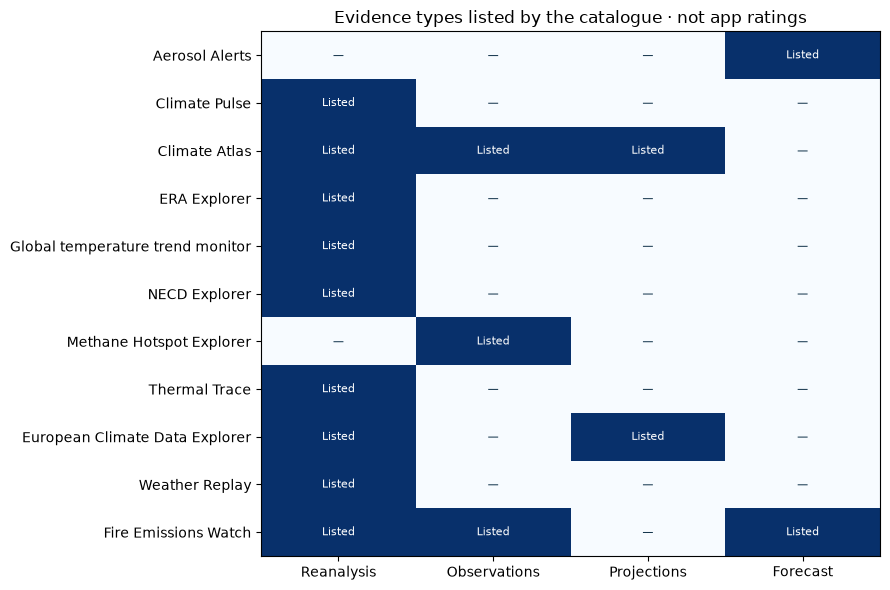

Blank = not listed for that app in this dated catalogue; it does not prove absence of a capability.


In [3]:
types = ["Reanalysis","Observations","Projections","Forecast"]
matrix = np.array([[int(kind.lower() in row.data_type.lower()) for kind in types] for row in apps.itertuples()])
fig, ax = plt.subplots(figsize=(9,6))
ax.imshow(matrix,cmap="Blues",vmin=0,vmax=1,aspect="auto")
ax.set(xticks=range(len(types)),xticklabels=types,yticks=range(len(apps)),yticklabels=apps.name,
       title="Evidence types listed by the catalogue · not app ratings")
for i in range(len(apps)):
    for j in range(len(types)):
        ax.text(j,i,"Listed" if matrix[i,j] else "—",ha="center",va="center",color="white" if matrix[i,j] else "#12334b",fontsize=8)
plt.tight_layout(); plt.show()
print("Blank = not listed for that app in this dated catalogue; it does not prove absence of a capability.")

## Build a reusable cross-app evidence journal

In [4]:
case_ids = ["weather-replay","era-explorer","thermal-trace"]  # Choose another investigation.
records=[]
for app in catalogue["entries"]:
    if app["id"] in case_ids:
        records.append({"app":app["name"],"url":app["url"],"task":app["exercise"],
          "review_status":"not yet inspected by learner","location":None,"selected_time":None,
          "forecast_issue_time_if_applicable":None,"variable_and_units":None,"spatial_support":None,
          "reference_period":None,"displayed_value":None,"dataset_version_and_licence":None,
          "share_url":None,"interpretation_limit":app["limitation"]})
display(pd.DataFrame(records)[["app","review_status","location","selected_time","displayed_value"]])
out=Path("exports"); out.mkdir(exist_ok=True)
(out/"copernicus-app-evidence-journal.json").write_text(json.dumps(records,indent=2),encoding="utf-8")
print("Fill the null fields only with inspected evidence. A blank is not zero and not a completed observation.")

,app,review_status,location,selected_time,displayed_value
0,ERA Explorer,not yet inspected by learner,None,None,None
1,Thermal Trace,not yet inspected by learner,None,None,None
2,Weather Replay,not yet inspected by learner,None,None,None


Fill the null fields only with inspected evidence. A blank is not zero and not a completed observation.


## Try it and explain

Complete one investigation with two or three apps. Fill the evidence journal, then explain which quantities can be compared directly and which need different spatial or temporal support.

**Interpretation check:** A matching location and date are necessary but not sufficient. Compare quantity, units, forecast issue/valid time, averaging support, baseline, dataset/version, and licence before joining numbers.

## Transfer to the official tools

Open the official catalogue to discover additions since this snapshot. Use the app overview and About panels to find datasets, tutorials, credits, and limitations; export only where the app supports it.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [Official Climate Pulse](https://pulse.climate.copernicus.eu/)
- [Copernicus Data Stores Applications](https://apps.climate.copernicus.eu/)
- [Catalogue team and scope](https://apps.climate.copernicus.eu/about)
- [Weather Replay introduction and video](https://climate.copernicus.eu/weather-replay-your-time-machine-revisit-past-weather)
- [ERA Explorer official training notebooks](https://apps.copernicus-climate.eu/c3s-apps/era-explorer/notebooks/intro.html)
- [NECD Explorer methods](https://apps.copernicus-climate.eu/nec-explorer/)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).